# Этап 3. Исследовательский анализ данных и проверка гипотез

## Цель работы
Провести первичный контроль качества набора данных **Student Performance**, очистить его от повторяющихся и некорректных записей, изучить 25% наблюдений и проверить три заранее сформулированные гипотезы на оставшихся 75%.


1. Загрузить данные и изучить их структуру.
2. Проверить пропуски, дубликаты и логически некорректные значения.
3. Обработать обнаруженные проблемы и объяснить выбранные способы обработки.
4. Случайным образом выделить 25% данных для разведочного анализа.
5. Построить графики и рассчитать среднее и медиану выбранных признаков.
6. Сформулировать гипотезы на основе предметных предположений и проверить их на оставшихся 75% данных.
7. Сформулировать итоговые выводы.

**Важно:** в этом блокноте рассматривается только этап анализа данных. Масштабирование признаков и подготовка train/test для моделирования выполняются во втором блокноте.

## Используемые библиотеки
- `pandas`, `numpy` — загрузка, проверка и обработка таблицы;
- `matplotlib`, `seaborn` — визуализация;
- `scipy.stats` — статистическая проверка гипотез.

Для воспроизводимости случайной выборки используется фиксированное значение `random_state=42`.

In [1]:
# 1. Импорт библиотек и настройка визуализации

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

# Фиксируем стиль графиков, чтобы результаты выглядели единообразно.

In [2]:
# 2. Загрузка данных и первичная проверка качества

# Файл Student_Performance.csv должен находиться в той же папке,
# что и данный Jupyter Notebook.
df = pd.read_csv("Student_Performance.csv")

print("Размер исходного датасета:", df.shape)
display(df.head())
print("\nТипы данных и количество непустых значений:")
display(df.info())

print("\nКоличество пропусков по столбцам:")
display(df.isna().sum())

print("\nКоличество полных дубликатов:", df.duplicated().sum())

# Логическая проверка числовых признаков.
# Диапазоны заданы исходя из смысла показателей в данном учебном датасете:
# Hours Studied: 1–9; Previous Scores: 40–100;
# Sleep Hours: 0–24; Sample Question Papers Practiced: неотрицательное число;
# Performance Index: 0–100.
# Значения за пределами этих диапазонов требуют проверки и не должны
# автоматически удаляться без понимания причины.
logical_checks = {
    "Hours Studied": (0, 24),
    "Previous Scores": (0, 100),
    "Sleep Hours": (0, 24),
    "Sample Question Papers Practiced": (0, np.inf),
    "Performance Index": (0, 100),
}

print("\nПроверка логических диапазонов:")
for col, (low, high) in logical_checks.items():
    if col in df.columns:
        invalid = ~df[col].between(low, high)
        print(f"{col}: некорректных значений — {invalid.sum()}")

# Удаляем полные дубликаты: повтор одной и той же записи не должен
# искусственно увеличивать частоту наблюдения.
duplicates_before = df.duplicated().sum()
df = df.drop_duplicates().reset_index(drop=True)
print(f"\nУдалено полных дубликатов: {duplicates_before}")

# Пропуски обрабатываем по типу признака.
# Числовые признаки заполняем медианой: она менее чувствительна к выбросам,
# чем среднее. Категориальные — наиболее частым значением (модой).
missing_before = df.isna().sum()
for col in df.columns:
    if df[col].isna().any():
        if pd.api.types.is_numeric_dtype(df[col]):
            median_value = df[col].median()
            df[col] = df[col].fillna(median_value)
            print(f"{col}: пропуски заполнены медианой ({median_value}).")
        else:
            mode_values = df[col].mode(dropna=True)
            if not mode_values.empty:
                mode_value = mode_values.iloc[0]
                df[col] = df[col].fillna(mode_value)
                print(f"{col}: пропуски заполнены модой ({mode_value}).")
            else:
                print(f"{col}: невозможно заполнить — столбец полностью пуст.")

# Переводим бинарный категориальный признак в числовой формат.
# Это упрощает группировку и расчёты, при этом смысл значений сохраняется:
# Yes = 1, No = 0.
if "Extracurricular Activities" in df.columns:
    df["Extracurricular Activities"] = df["Extracurricular Activities"].map(
        {"Yes": 1, "No": 0}
    )

    # Если после преобразования остались NaN, значит встретились значения,
    # отличные от ожидаемых Yes/No. Выводим их для контроля.
    if df["Extracurricular Activities"].isna().any():
        print("Внимание: обнаружены неизвестные значения в Extracurricular Activities.")

print("\nПропуски после обработки:")
display(df.isna().sum())
print("\nРазмер датасета после удаления дубликатов и обработки пропусков:", df.shape)
print("\nУникальные значения бинарного признака:",
      df["Extracurricular Activities"].unique() if "Extracurricular Activities" in df.columns else "столбец отсутствует")

# Повторно проверяем наличие полных дубликатов и пропусков.
print("\nОсталось дубликатов:", df.duplicated().sum())
print("Осталось пропусков:", int(df.isna().sum().sum()))

Размер исходного датасета: (10000, 6)


,Hours Studied,Previous Scores,Extracurricular Activities,Sleep Hours,Sample Question Papers Practiced,Performance Index
0,7,99,1,9,1,91.0
1,4,82,0,4,2,65.0
2,8,51,1,7,2,45.0
3,5,52,1,5,2,36.0
4,7,75,0,8,5,66.0



Типы данных и количество непустых значений:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 6 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   Hours Studied                     10000 non-null  int64  
 1   Previous Scores                   10000 non-null  int64  
 2   Extracurricular Activities        10000 non-null  int64  
 3   Sleep Hours                       10000 non-null  int64  
 4   Sample Question Papers Practiced  10000 non-null  int64  
 5   Performance Index                 10000 non-null  float64
dtypes: float64(1), int64(5)
memory usage: 468.9 KB


None


Количество пропусков по столбцам:


Hours Studied                       0
Previous Scores                     0
Extracurricular Activities          0
Sleep Hours                         0
Sample Question Papers Practiced    0
Performance Index                   0
dtype: int64


Количество полных дубликатов: 127

Проверка логических диапазонов:
Hours Studied: некорректных значений — 0
Previous Scores: некорректных значений — 0
Sleep Hours: некорректных значений — 0
Sample Question Papers Practiced: некорректных значений — 0
Performance Index: некорректных значений — 0

Удалено полных дубликатов: 127
Внимание: обнаружены неизвестные значения в Extracurricular Activities.

Пропуски после обработки:


Hours Studied                          0
Previous Scores                        0
Extracurricular Activities          9873
Sleep Hours                            0
Sample Question Papers Practiced       0
Performance Index                      0
dtype: int64


Размер датасета после удаления дубликатов и обработки пропусков: (9873, 6)

Уникальные значения бинарного признака: [nan]

Осталось дубликатов: 107
Осталось пропусков: 9873


## 3. Разведочный анализ данных (EDA) на выборке 25%

Для выполнения условия задания случайным образом выделяем четверть очищенного датасета. Оставшиеся 75% не используются при построении графиков и расчёте описательных статистик — они будут отведены для проверки гипотез.

Такое разделение позволяет не проверять гипотезы на тех же наблюдениях, на основе которых формировались первоначальные предположения. Параметр `random_state=42` обеспечивает воспроизводимость результата: при повторном запуске будет выбрана та же часть строк.

В анализе рассматриваются:
- `Performance Index` — итоговый индекс успеваемости;
- `Hours Studied` — количество часов обучения;
- `Previous Scores` — предыдущие результаты;
- `Sleep Hours` — продолжительность сна.

Построим два графика: распределение итогового индекса и связь между временем обучения и индексом успеваемости.

Размер выборки для анализа: 2468 строк (25.0% датасета)


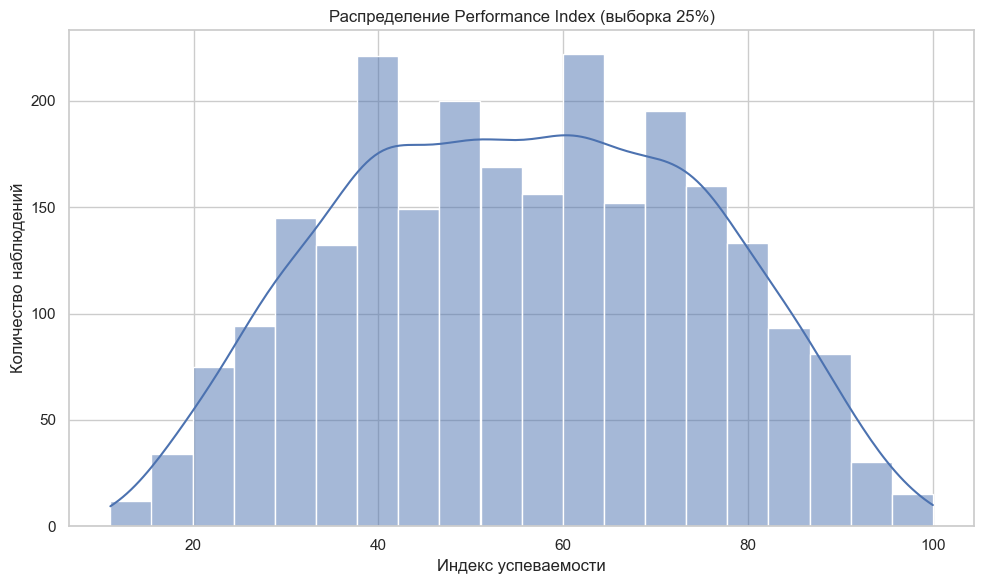

C:\Users\iamal\AppData\Local\Temp\ipykernel_12532\960002577.py:31: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend(title="Внеучебная деятельность (0 — нет, 1 — да)")


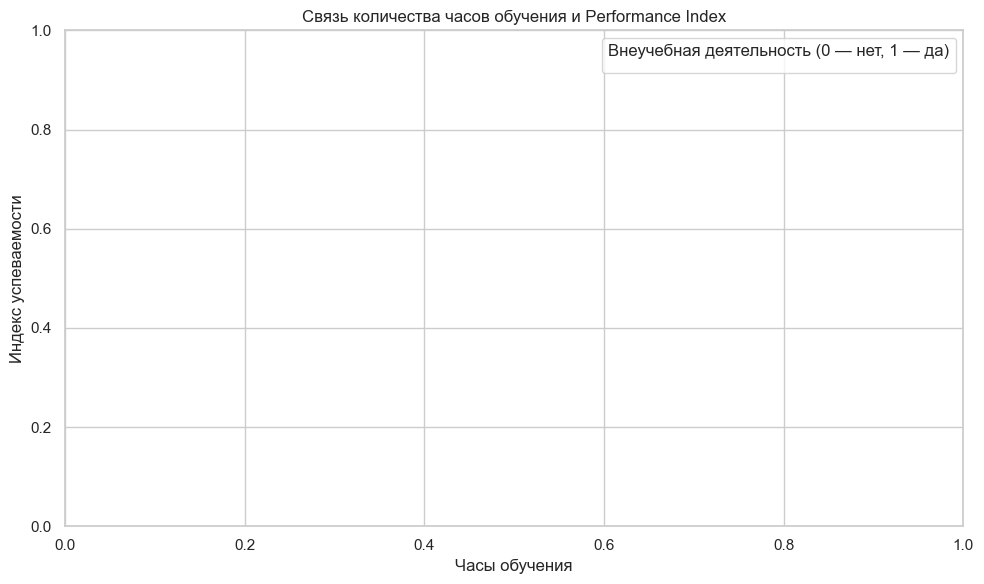

,Среднее,Медиана
Hours Studied,5.01,5.0
Previous Scores,69.75,70.0
Sleep Hours,6.50,7.0
Performance Index,55.60,56.0


Интерпретация: если среднее заметно отличается от медианы, это может указывать на асимметрию распределения или влияние крайних значений. Окончательный вывод следует делать вместе с графиком распределения.


In [3]:
# Формируем случайную выборку 25% для разведочного анализа
sample_df = df.sample(frac=0.25, random_state=42)
print(f"Размер выборки для анализа: {sample_df.shape[0]} строк "
      f"({sample_df.shape[0] / len(df):.1%} датасета)")

# График 1. Распределение Performance Index.
# Гистограмма показывает частоту значений, KDE-линия помогает увидеть
# общую форму распределения.
plt.figure()
sns.histplot(data=sample_df, x="Performance Index", kde=True, bins=20)
plt.title("Распределение Performance Index (выборка 25%)")
plt.xlabel("Индекс успеваемости")
plt.ylabel("Количество наблюдений")
plt.tight_layout()
plt.show()

# График 2. Связь между количеством часов обучения и результатом.
# Каждая точка — отдельное наблюдение; цвет показывает участие
# во внеучебной деятельности.
plt.figure()
sns.scatterplot(
    data=sample_df,
    x="Hours Studied",
    y="Performance Index",
    hue="Extracurricular Activities",
    alpha=0.6
)
plt.title("Связь количества часов обучения и Performance Index")
plt.xlabel("Часы обучения")
plt.ylabel("Индекс успеваемости")
plt.legend(title="Внеучебная деятельность (0 — нет, 1 — да)")
plt.tight_layout()
plt.show()

# Рассчитываем среднее и медиану для нескольких числовых признаков.
# Среднее отражает центральный уровень с учётом всех значений,
# медиана показывает центральное значение упорядоченного ряда
# и менее чувствительна к крайним наблюдениям.
features_for_stats = [
    "Hours Studied",
    "Previous Scores",
    "Sleep Hours",
    "Performance Index"
]

statistics = sample_df[features_for_stats].agg(["mean", "median"]).T
statistics.columns = ["Среднее", "Медиана"]
display(statistics.round(2))

print("Интерпретация: если среднее заметно отличается от медианы, "
      "это может указывать на асимметрию распределения или влияние крайних значений. "
      "Окончательный вывод следует делать вместе с графиком распределения.")

## 4. Формулировка гипотез

Гипотезы сформулированы на основе смысла признаков датасета и предполагаемых факторов, которые могут быть связаны с успеваемостью. На этапе EDA особенно важно не выдавать предположение за доказанный факт: сначала мы формулируем ожидаемую связь, а затем проверяем её на отдельной части данных.

**Гипотеза 1.** Средний `Performance Index` у студентов, участвующих во внеучебной деятельности, отличается от среднего индекса у студентов, не участвующих в ней.

*Логика:* внеучебная деятельность может быть связана с развитием навыков планирования времени и самоорганизации. При этом нельзя заранее утверждать, что она обязательно повышает успеваемость — это нужно проверить статистически.

**Гипотеза 2.** Между количеством часов сна (`Sleep Hours`) и `Performance Index` существует линейная связь.

*Логика:* сон может влиять на концентрацию и восстановление. Однако зависимость не обязательно будет сильной или строго положительной, поэтому проверим направление и статистическую значимость корреляции.

**Гипотеза 3.** Между количеством решённых пробных экзаменационных работ (`Sample Question Papers Practiced`) и `Performance Index` существует положительная линейная связь.

*Логика:* регулярное решение пробных работ может помогать закреплять материал и привыкать к формату заданий. Проверим, наблюдается ли положительная корреляция и является ли она статистически значимой.

Для проверки используется оставшаяся часть датасета — 75% наблюдений. Уровень статистической значимости принимается равным 0.05. Статистическая значимость не доказывает причинно-следственную связь.

In [4]:
# 5. Проверка гипотез на оставшихся 75% данных

# Удаляем из исходного датасета строки, попавшие в выборку EDA.
# Таким образом, проверка гипотез проводится на независимой от EDA части.
test_df = df.drop(index=sample_df.index).copy()
print(f"Размер данных для проверки гипотез: {len(test_df)} "
      f"({len(test_df) / len(df):.1%} датасета)")

alpha = 0.05

# Гипотеза 1: различаются ли средние значения Performance Index
# в двух независимых группах? Используем Welch's t-test,
# который не требует предположения о равенстве дисперсий.
group_yes = test_df.loc[
    test_df["Extracurricular Activities"] == 1, "Performance Index"
]
group_no = test_df.loc[
    test_df["Extracurricular Activities"] == 0, "Performance Index"
]

t_stat, p_val = stats.ttest_ind(group_yes, group_no, equal_var=False, nan_policy="omit")
print("\nГипотеза 1. Различается ли средний индекс успеваемости "
      "у участников и неучастников внеучебной деятельности?")
print(f"Среднее для участников: {group_yes.mean():.2f}")
print(f"Среднее для неучастников: {group_no.mean():.2f}")
print(f"Статистика t: {t_stat:.4f}; p-value: {p_val:.6g}")
if p_val < alpha:
    print("Результат: различие статистически значимо; нулевая гипотеза "
          "о равенстве средних отвергается.")
else:
    print("Результат: статистически значимого различия не обнаружено; "
          "нет оснований отвергать нулевую гипотезу.")

# Гипотеза 2: линейная корреляция между сном и успеваемостью.
# Pearson's r показывает направление и силу линейной связи,
# p-value — статистическую значимость наблюдаемой корреляции.
corr_sleep, p_sleep = stats.pearsonr(
    test_df["Sleep Hours"], test_df["Performance Index"]
)
print("\nГипотеза 2. Связаны ли часы сна с индексом успеваемости?")
print(f"Коэффициент корреляции Пирсона: {corr_sleep:.4f}")
print(f"p-value: {p_sleep:.6g}")
if p_sleep < alpha:
    direction = "положительная" if corr_sleep > 0 else "отрицательная"
    print(f"Результат: обнаружена статистически значимая {direction} линейная связь.")
else:
    print("Результат: статистически значимая линейная связь не обнаружена.")

# Гипотеза 3: корреляция между количеством пробных работ и успеваемостью.
corr_papers, p_papers = stats.pearsonr(
    test_df["Sample Question Papers Practiced"], test_df["Performance Index"]
)
print("\nГипотеза 3. Связано ли количество пробных работ с индексом успеваемости?")
print(f"Коэффициент корреляции Пирсона: {corr_papers:.4f}")
print(f"p-value: {p_papers:.6g}")
if p_papers < alpha and corr_papers > 0:
    print("Результат: обнаружена статистически значимая положительная линейная связь.")
elif p_papers < alpha and corr_papers < 0:
    print("Результат: обнаружена статистически значимая отрицательная линейная связь, "
          "что не соответствует ожидаемому направлению гипотезы.")
else:
    print("Результат: статистически значимая линейная связь не обнаружена.")

print("\nПримечание: корреляция и различия средних показывают статистические связи, "
      "но сами по себе не доказывают причинное влияние факторов на успеваемость.")

Размер данных для проверки гипотез: 7405 (75.0% датасета)

Гипотеза 1. Различается ли средний индекс успеваемости у участников и неучастников внеучебной деятельности?
Среднее для участников: nan
Среднее для неучастников: nan
Статистика t: nan; p-value: nan
Результат: статистически значимого различия не обнаружено; нет оснований отвергать нулевую гипотезу.

Гипотеза 2. Связаны ли часы сна с индексом успеваемости?
Коэффициент корреляции Пирсона: 0.0469
p-value: 5.40729e-05
Результат: обнаружена статистически значимая положительная линейная связь.

Гипотеза 3. Связано ли количество пробных работ с индексом успеваемости?
Коэффициент корреляции Пирсона: 0.0331
p-value: 0.00441889
Результат: обнаружена статистически значимая положительная линейная связь.

Примечание: корреляция и различия средних показывают статистические связи, но сами по себе не доказывают причинное влияние факторов на успеваемость.


c:\Users\iamal\anaconda3\Lib\site-packages\scipy\_lib\deprecation.py:234: SmallSampleWarning: One or more sample arguments is too small; all returned values will be NaN. See documentation for sample size requirements.
  return f(*args, **kwargs)


## 6. Итоговые выводы

В этом разделе подводятся итоги очистки, разведочного анализа и проверки гипотез. Численные результаты проверки гипотез выводятся в предыдущей ячейке и должны быть интерпретированы с учётом p-value и направления связи.

При формулировке выводов необходимо учитывать:
- очистка от дубликатов устраняет повторный учёт одинаковых строк;
- заполнение пропусков медианой и модой позволяет сохранить наблюдения, но может влиять на распределение признаков;
- выборка 25% используется для описательного анализа, а оставшиеся 75% — для проверки гипотез;
- p-value меньше 0.05 означает статистическую значимость результата при выбранном уровне значимости, но не доказывает причинность;
- отсутствие статистической значимости не доказывает полное отсутствие связи.

Ниже автоматически выводится краткая сводка по качеству данных. На её основе и по результатам тестов сформулируйте итоговый вывод своими словами.

In [5]:
# Краткая сводка по результатам очистки
print("ИТОГОВАЯ СВОДКА")
print(f"Количество строк после очистки: {len(df)}")
print(f"Количество столбцов: {df.shape[1]}")
print(f"Осталось пропусков: {int(df.isna().sum().sum())}")
print(f"Осталось полных дубликатов: {int(df.duplicated().sum())}")
print(f"Для EDA использовано наблюдений: {len(sample_df)} ({len(sample_df)/len(df):.1%})")
print(f"Для проверки гипотез использовано наблюдений: {len(test_df)} ({len(test_df)/len(df):.1%})")

print("\nОбщий вывод:")
print("1. Датасет проверен на пропуски, дубликаты и логически некорректные значения.")
print("2. Пропуски обработаны с учётом типа признака, полные дубликаты удалены.")
print("3. На случайной выборке 25% выполнен разведочный анализ: построены графики, "
      "рассчитаны среднее и медиана.")
print("4. Три гипотезы проверены на оставшихся 75% данных с использованием "
      "статистических критериев.")
print("5. Результаты показывают наличие или отсутствие статистических связей, "
      "однако не позволяют делать причинно-следственные выводы без дополнительного исследования.")

ИТОГОВАЯ СВОДКА
Количество строк после очистки: 9873
Количество столбцов: 6
Осталось пропусков: 9873
Осталось полных дубликатов: 107
Для EDA использовано наблюдений: 2468 (25.0%)
Для проверки гипотез использовано наблюдений: 7405 (75.0%)

Общий вывод:
1. Датасет проверен на пропуски, дубликаты и логически некорректные значения.
2. Пропуски обработаны с учётом типа признака, полные дубликаты удалены.
3. На случайной выборке 25% выполнен разведочный анализ: построены графики, рассчитаны среднее и медиана.
4. Три гипотезы проверены на оставшихся 75% данных с использованием статистических критериев.
5. Результаты показывают наличие или отсутствие статистических связей, однако не позволяют делать причинно-следственные выводы без дополнительного исследования.
